# Fitting a master catalog: Abell S1063

This tutorial fits Abell S1063 with its **master catalog**, the merge of the three published catalogs of the cluster
under `catalogs/as1063/`, and uses the reliability the master gives every image and member.

A master catalog (`catalogs/<cluster>/master/`) is built by `scripts/build_master_catalog.py` from the per-paper
folders: each paper is shifted onto the frame of a base paper (here the JWST catalog of Diego et al. 2026), the images
are matched across papers, and every system any paper lists is kept, ranked by how well it is established. Each image
carries the prior that it belongs to its system, each member the prior that it belongs to the cluster. One
`images.yaml` serves every kind of fit: the run decides which images to trust.

**Runtime.** About 45 minutes on a laptop CPU (4 chains; 15 for the search, the rest sampling and outputs), with a short search and short chains: enough to see a
fit and its diagnostics, not a converged posterior. The last section lists what to change for a fit you can use.

**Before you start.** Run the notebook from the repository root, in an environment with kappaccino installed (see
the installation page).

## Set up the CPU chains

NUTS runs one chain per JAX CPU device. The devices have to be set before anything starts JAX, so this comes first.

In [1]:
from kappaccino.cpu_runtime import configure_cpu_runtime

configure_cpu_runtime(4, "parallel")    # 4 chains

CPUPlan(chains=4, chain_method='parallel', threads_per_chain=None, jax_cpu_devices=4, available_cpu_ids=(0, 1, 2, 3, 4, 5, 6, 7), selected_cpu_ids=(0, 1, 2, 3, 4, 5, 6, 7), affinity_supported=False, blas_threads=1)

In [2]:
%matplotlib inline
import os
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from IPython.utils.capture import capture_output

from kappaccino.config import LikelihoodConfig, SamplingConfig, ShearHaloConfig
from kappaccino.io.image_catalog import load_image_catalog
from kappaccino.io.lenstool_par import config_from_lenstool_par
from kappaccino.io.member_catalog import load_member_catalog
from kappaccino.pipeline import dry_run, run
from kappaccino.priors import describe, truncated_lognormal

if Path.cwd().name == "notebooks":       # run from the repository root, where the catalog paths are relative to
    os.chdir("..")
plt.style.use("src/kappaccino/plotting/style.mplstyle")
master = Path("catalogs/as1063/master")

## The master catalog

`sources.yaml` lists the papers, the base paper, and how each paper's own quality flags map to a score (Diego et al.
rank their images A and B); `decisions.yaml` holds the choices made by hand, each with its reason. Here there is one:
the base paper's members leave out the BCG, so Bergamini's BCG enters as a halo of its own.

In [3]:
print((master / "sources.yaml").read_text())
print((master / "decisions.yaml").read_text())

# Papers merged into the Abell S1063 master catalog (scripts/build_master_catalog.py).  Paths are relative to this folder.
cluster: as1063
base: diego2026               # JWST frame, knots, parities; its systems enter unchanged
match_radius_arcsec: 0.5      # after each paper is shifted onto the base frame
dz_max: 0.01                  # |dz| / (1 + z) above which two spectroscopic redshifts conflict
z_cluster: 0.348               # members: a spectroscopic z within member_dz (1 + z) of it gives p_member 1
papers:
  diego2026:
    images: ../diego2026/images.yaml
    quality:                  # image notes -> quality (first match wins; 1 otherwise)
      'rank B': 0.7
    members: ../diego2026/members.yaml
    z_kind: spec              # rank A plus system 60, all with the published spectroscopic z (diego2026/README.md)
  bergamini2019:
    images: ../bergamini2019/images.yaml
    members: ../bergamini2019/members.cat
    member_band: F160W        # the potfile magnitudes are F160W Kro

`crossmatch.yaml` records how each paper was moved onto the base frame (the median offset of its matched images,
measured by the build), and for every master system the systems of each paper it matches, the number of independent
papers listing it, its redshift kind, and its **tier**:

| tier | rule | reliability |
|---|---|---|
| diamond | spectroscopic z, two or more independent papers, good flags | 1.0 |
| gold | spectroscopic z, good flags | 0.9 |
| silver | spectroscopic z or two independent papers | 0.7 |
| bronze | fair flags | 0.4 |
| copper | otherwise | 0.15 |

Bergamini et al. (2019) reuse the Caminha et al. (2016) image positions, so the two count as one paper
(`derived_from`). The four B systems are in that pair only, and CM50 and CM51 have no redshift (free in Caminha's
model): they stay in the catalog with z = 0.

In [4]:
crossmatch = yaml.safe_load((master / "crossmatch.yaml").read_text())
for paper, frame in crossmatch["frames"].items():
    print(f"{paper:14s} {frame}")
systems = pd.DataFrame([{"system": name, "tier": entry["tier"], "reliability": entry["reliability"], "z kind": entry["z_kind"],
                         "papers": entry["independent_papers"],
                         **{paper: ", ".join(ids) for paper, ids in entry["papers"].items()}}
                        for name, entry in crossmatch["systems"].items()]).fillna("")
print(systems.tier.value_counts().to_dict())
systems

diego2026      {'applied_arcsec': [0.0, 0.0], 'note': 'base frame'}
bergamini2019  {'applied_arcsec': [-0.0038, 0.0178], 'n_matches': 44, 'median_residual_arcsec': 0.0568}
caminha2016    {'applied_arcsec': [-0.0038, 0.0178], 'n_matches': 44, 'median_residual_arcsec': 0.0568}
{'diamond': 16, 'gold': 8, 'bronze': 2, 'silver': 1}


,system,tier,reliability,z kind,papers,diego2026,bergamini2019,caminha2016
0,D1,diamond,1.0,spec,2,D1,2,2
1,D5,diamond,1.0,spec,2,D5,3,3
2,D8,diamond,1.0,spec,2,D8,13,13
3,D9,diamond,1.0,spec,2,D9,4,4
4,D12,diamond,1.0,spec,2,D12,6,6
5,D18,diamond,1.0,spec,2,D18,8,8
6,D19,diamond,1.0,spec,2,D19,23,23
7,D22,gold,0.9,spec,1,D22,,
8,D23,diamond,1.0,spec,2,D23,14,14
9,D24,diamond,1.0,spec,2,D24,18,18


Every image (or knot) has a `prior`: its system's reliability, lowered when the paper's own flag for that image is
poor. Diego's system 60 is spectroscopic, but its images are rank B (quality 0.7): the system is silver, and their
prior is 0.7 x 0.7.

         size   min   max
tier                     
bronze      5  0.40  0.40
diamond   108  1.00  1.00
gold       22  0.90  0.90
silver      3  0.49  0.49


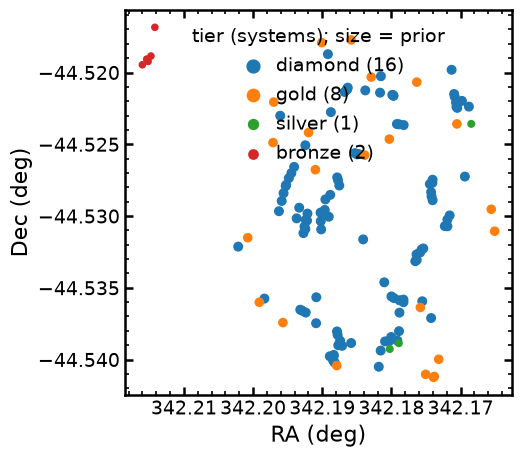

In [5]:
images = load_image_catalog(master / "images.yaml", sigma_inst_arcsec=0.01)
images["tier"] = images.system_id.map({name: entry["tier"] for name, entry in crossmatch["systems"].items()})
print(images.groupby("tier").association_prior.agg(["size", "min", "max"]))

colors = {"diamond": "C0", "gold": "C1", "silver": "C2", "bronze": "C3", "copper": "C4"}
fig, ax = plt.subplots(figsize=(5, 5))
for tier, color in colors.items():
    sel = images[images.tier == tier]
    if len(sel):
        ax.scatter(sel.ra, sel.dec, s=8 + 30 * sel.association_prior, color=color, label=f"{tier} ({sel.system_id.nunique()})")
ax.invert_xaxis()
ax.set_xlabel("RA (deg)")
ax.set_ylabel("Dec (deg)")
ax.legend(title="tier (systems); size = prior")
display(fig)
plt.close(fig)

The members have `p_member`: 1 with a spectroscopic redshift in the cluster, a BCG role or measured kinematics; 0.9
when two independent papers select the galaxy; 0.7 when one does. Members only an older paper lists are kept, at 0.7.

In [6]:
members = load_member_catalog(master / "members.yaml", (0, 0.0, 0.0))
members.catalog_p_member.value_counts().sort_index(ascending=False)

catalog_p_member
1.0     47
0.9     93
0.7    237
Name: count, dtype: int64

## The model

The mass model is the one of Bergamini et al. (2019) in their Lenstool file: a cluster-scale dPIE, a second halo to
the north-east, three fixed gas components and the members on a luminosity scaling relation. `config_from_lenstool_par`
reads it, with the master's images and members in place of the files it names.

In [7]:
config = config_from_lenstool_par(
    "catalogs/as1063/bergamini2019/source/Bergamini_RXCJ2248_lenstool_Normal.par",
    image_catalog=master / "images.yaml",
    member_catalog=master / "members.yaml",
    output_dir="results/tutorial",
    run_name="as1063_master",
)
model = config.model
for halo in model.large_halos:
    free = ", ".join(f"{name} {describe(prior)}" for name, prior in halo.priors.items()) or "fixed"
    print(f"halo {halo.id}: sigma {halo.v_disp:.0f} km/s; {free}")
population = model.member_populations[0]
print(f"members: {population.catalog_path}, mag0 = {population.mag0}, sigma = {population.sigma} km/s, rcut = {population.cutkpc:.0f} kpc")

halo 1: sigma 1500 km/s; v_disp TruncatedNormal(7.076, 0.1655, [6.908, inf]) in log, e1 Uniform(0.02182, 0.1545), e2 Uniform(-0.4973, -0.1985), x_centre Uniform(-2, 4), y_centre Uniform(-2, 2), core_radius_kpc Uniform(3.203, 5.149) in log
halo 2: sigma 300 km/s; v_disp TruncatedNormal(5.868, 0.8326, [-9.21, inf]) in log, x_centre Uniform(-100, 50), y_centre Uniform(-50, 70)
halo 3: sigma 356 km/s; fixed
halo 4: sigma 443 km/s; fixed
halo 5: sigma 250 km/s; fixed
members: catalogs/as1063/master/members.yaml, mag0 = 16.176001, sigma = 310.0 km/s, rcut = 49 kpc


## Using the priors

- **Trusted images.** `trusted_prior_min=0.8` keeps the images whose prior is at least 0.8, the diamond and gold
  systems without their poorly flagged images, as the families that constrain the lens. The others stay in the file;
  the last section shows how to fit them too.
- **Uncertain members.** `membership="marginalize"` sums each member's membership over its `p_member`: a member at 0.7
  enters with 70% of its mass and the variance of the rest (with `membership_max_enumerated=0` none is enumerated
  exactly, which keeps the fit fast).
- **External shear**, free; the production **likelihood** (image-plane GP plus a Gaussian random field of unmodeled
  mass with a knee spectrum); a short **search and sampling**: 32 starts, 150 warmup and 100 samples per chain.

In [8]:
grf_likelihood = LikelihoodConfig(
    likelihood_mode="gp_image_plane",
    gp_kernel="knee",
    gp_blocks="all",
    gp_knee_project_modes=("translation", "convergence", "shear"),
    sigma_sel_prior=None,
    gp_knee_gamma=4.0,
    gp_knee_gamma_prior=None,
    gp_knee_scales_arcsec=(0.2, 100.0),
    gp_knee_prior=truncated_lognormal(6.0, 0.6, low=2.5, high=8.0),
    gp_knee_start_arcsec=6.0,
    gp_sigma_alpha_prior=truncated_lognormal(0.08, 0.5, low=1e-4, high=0.5),
    gp_sigma_alpha_start_arcsec=0.08,
    gp_knee_ell_prior=truncated_lognormal(1.0, 0.4, low=0.4, high=3.0),
    gp_knee_ell_start_arcsec=1.0,
)

config = replace(
    config,
    model=replace(model, large_halos=model.large_halos + (ShearHaloConfig.free("S1", population.z_lens, gamma_upper=0.3),),
                  image_constraints=replace(model.image_constraints, trusted_prior_min=0.8)),
    likelihood=grf_likelihood,
    search=replace(config.search, n_starts=32),
    sampling=SamplingConfig(warmup=150, samples=100, max_tree_depth=8, target_accept=0.8),
    members=replace(config.members, centering="auto", membership="marginalize", membership_max_enumerated=0),
    runtime=replace(config.runtime, quiet=True),
).validate()

## Check the configuration

`dry_run` builds the model and classifies the members without fitting or writing anything. The BCG (B1809) appears
as an independent member halo, as `decisions.yaml` asks.

In [9]:
with capture_output():
    summary = dry_run(config)
{key: summary[key] for key in ("likelihood", "parameters", "images", "families", "members", "sampling")}

{'likelihood': 'grf_gp (GRF of unmodelled mass with a knee spectrum + image-plane GP, all blocks)',
 'parameters': 869,
 'images': 130,
 'families': 45,
 'members': 376,
 'sampling': {'chains': 4, 'warmup': 150, 'samples': 100, 'max_tree_depth': 8}}

## Run the fit

`run` does the multi-start search for the posterior mode (**init**), then NUTS from it (**final**), and writes the
tables and figures under `results/tutorial/as1063_master/`. Running the cell again reloads the finished stages.

In [10]:
with capture_output():
    result = run(config)
print({k: f"{v / 60:.1f} min" for k, v in result.timing.items()})
root = result.paths.root

{'sampling': '0.0 min', 'outputs': '7.1 min', 'init': '0.1 min', 'total': '7.1 min'}


### Did it work?

The last line of the init log says whether the search is robust (several starts reach the best basin) or fragile;
`run_summary.txt` gives the image recovery, the residuals and the sampler diagnostics.

In [11]:
print((root / "init/logs/init.log").read_text().splitlines()[-1][20:])
print((root / "final/tables/run_summary.txt").read_text())

[     0.0s] [init] complete init stage found; loading the saved start
Run summary                                                                     
  Run                                                                           
    name                                  as1063_master                         
    output                                results/tutorial/as1063_master/final  
    stages                                init resumed, final resumed           
                                                                                
  Data and model                                                                
    images, families                      130, 45                               
    members: exact, far-field             224, 152                              
    sampled parameters                    869                                   
    global parameters, dof                27, 133                               
                                       

In [12]:
convergence = pd.read_csv(root / "final/tables/chain_convergence.csv")
print(f"{(convergence.split_rhat > 1.01).sum()} of {len(convergence)} parameters have R-hat > 1.01")
convergence.sort_values("split_rhat", ascending=False).head(8).round(2)

206 of 869 parameters have R-hat > 1.01


,parameter,split_rhat,ess
8,2.y_centre,3.83,2.23
7,2.x_centre,3.54,2.28
6,2.v_disp,2.18,2.67
17,independent_member_potfile_B1809.v_disp,1.68,4.17
4,1.y_centre,1.55,3.47
5,1.core_radius_kpc,1.55,3.83
16,independent_member_potfile_B1809.cut_excess_kpc,1.52,3.90
9,S1.gamma1,1.35,6.11


With chains this short, many parameters are far above R-hat 1.01 (halo 2, to the north-east, and the BCG most of all): read
the results below as a **best-fit model with indicative uncertainties**. The best fit itself is rough too: an image-plane
rms of 1.7" against about 0.5" for the published models of the cluster, because 32 search starts are few for 869
parameters and the second halo is barely constrained by these images. The last section lists what to change.

## The posterior

The global parameters: the halos, the shear, the member scaling relation and the error model.

In [13]:
posterior = pd.read_csv(root / "final/tables/posterior_summary.csv")
globals_ = posterior[posterior.family.isin(["large", "scaling", "member_velocity_scatter", "error_scale"])]
globals_[["parameter", "median", "p16", "p84", "best_fit", "r_hat"]].round(3)

,parameter,median,p16,p84,best_fit,r_hat
0,1.v_disp,1065.201,1052.122,1076.899,1058.194,1.060
1,1.e1,0.076,0.067,0.088,0.078,1.312
2,1.e2,-0.290,-0.305,-0.279,-0.278,1.124
3,1.x_centre,-0.144,-0.683,0.315,-1.033,1.304
4,1.y_centre,0.380,0.050,1.062,0.844,1.553
5,1.core_radius_kpc,72.835,69.208,78.829,74.042,1.546
6,2.v_disp,101.486,62.138,215.465,137.071,1.893
7,2.x_centre,-21.613,-58.785,2.048,11.792,3.535
8,2.y_centre,9.224,-17.640,43.583,51.931,3.827
9,S1.gamma1,-0.006,-0.014,-0.000,-0.009,1.349


## Residuals by tier

`image_fit_quality.csv` gives the best-fit image-plane residual of each trusted image. Joined with the tiers, it shows
whether the diamond systems (confirmed by two independent papers) fit better than the gold ones (one paper).

,images,rms,median,max
tier,,,,
diamond,108,1.657,1.144,4.525
gold,22,1.962,1.291,3.693


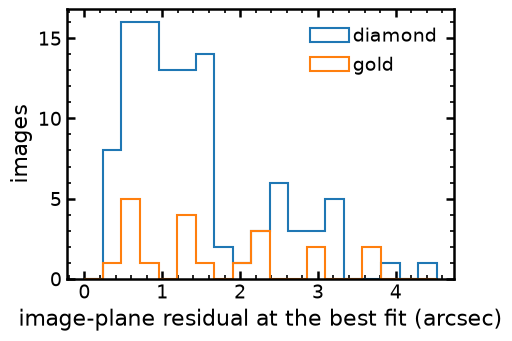

,image_label,tier,association_prior,z_source,image_residual_arcsec,image_recovery_status
117,D24.b,diamond,1.0,4.113,4.525,recovered
1,D19A.b,diamond,1.0,0.730,3.874,recovered
77,D22.a,gold,0.9,3.116,3.693,recovered
75,D37.a,gold,0.9,3.082,3.690,recovered
116,D24.a,diamond,1.0,4.113,3.304,recovered
36,D5B.a,diamond,1.0,1.261,3.186,recovered
24,D1C.a,diamond,1.0,1.229,3.155,recovered
6,D19C.a,diamond,1.0,0.730,3.123,recovered


In [14]:
fit = pd.read_csv(root / "final/tables/image_fit_quality.csv")
fit = fit.merge(images[["image_label", "system_id", "tier", "association_prior"]], on="image_label", how="left")
display(fit.groupby("tier").image_residual_arcsec.agg(images="size", rms=lambda r: np.sqrt(np.mean(r ** 2)), median="median", max="max").round(3))

fig, ax = plt.subplots(figsize=(5, 3.5))
bins = np.linspace(0, fit.image_residual_arcsec.max(), 20)
for tier in ("diamond", "gold"):
    ax.hist(fit.loc[fit.tier == tier, "image_residual_arcsec"], bins=bins, histtype="step", lw=1.5, color=colors[tier], label=tier)
ax.set_xlabel("image-plane residual at the best fit (arcsec)")
ax.set_ylabel("images")
ax.legend()
display(fig)
plt.close(fig)
fit.sort_values("image_residual_arcsec", ascending=False)[
    ["image_label", "tier", "association_prior", "z_source", "image_residual_arcsec", "image_recovery_status"]].head(8).round(3)

A system that fits much worse than the rest is the first place to look for a misidentified image or a wrong redshift;
the master records each such choice in `decisions.yaml` (`set_z`, `set_tier`, `exclude`) with its reason, and the next
build carries it.

## Fitting the uncertain images too

The images below the trusted prior are still in the catalog. Adding a partition configuration without a separate
table makes them the uncertain images of the slot mixture: each may belong to its catalog system (with its prior as
the weight of that option), to a new source shared with other uncertain images, or to nothing, and NUTS sums over the
choices while it samples the lens. CM50 and CM51, which have no redshift, get theirs sampled.

```python
from kappaccino.config import PartitionConfig

config = replace(config, partition=PartitionConfig(), paths=replace(config.paths, run_name="as1063_master_slots")).validate()
```

## From here to a production fit

- More search starts: `search=replace(config.search, n_starts=256)`.
- Longer chains: raise `warmup` and `samples` until the maximum R-hat is below 1.01 and the minimum ESS is in the
  hundreds; `final/logs/final.log` names the slow directions.
- Exact membership for the members that matter most: raise `membership_max_enumerated` (each one doubles the cost).
- A changed configuration needs a new `run_name`: `run` refuses to resume a run with a different configuration.
- After a new paper or decision, rebuild the master (`python scripts/build_master_catalog.py catalogs/as1063/master`).